# 3. Functions and Classes: Exercise

Name: Xiuning Zhang

In [2]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

## 1. Functions
Define the following functions and show some sample outputs.  
1) Factorial of n: $1 \times 2 \times \cdots \times n$.

In [1]:
def factorial(n):
    """factorial of n"""
    fact = 1
    for i in range(1, n + 1):
        fact *= i
    return fact

In [6]:
def factorial(n):
    """factorial of n"""
    if n == 1:
        return 1
    else:
        return n * factorial(n-1)

In [7]:
for n in range(1, 10):
    print(factorial(n))

1
2
6
24
120
720
5040
40320
362880


2) For a circle of radius r (default r=1), given x coordinate, return possible y coordinates (two, one, or None).

In [12]:
def circley(x, r=1):
    """y values of a circle with radius r"""
    if abs(x) > r:
        return 'None'
    elif abs(x) == r:
        return 0
    else:
        y = np.sqrt(r**2 - x**2)
        return [y, -y]

print(circley(-0.5, 1))
print(circley(1, 1))
print(circley(2, 1))

[np.float64(0.8660254037844386), np.float64(-0.8660254037844386)]
0
None


3) Draw a star-like shape with n vertices, every m-th vertices connected, with default of n=5 and m=2.

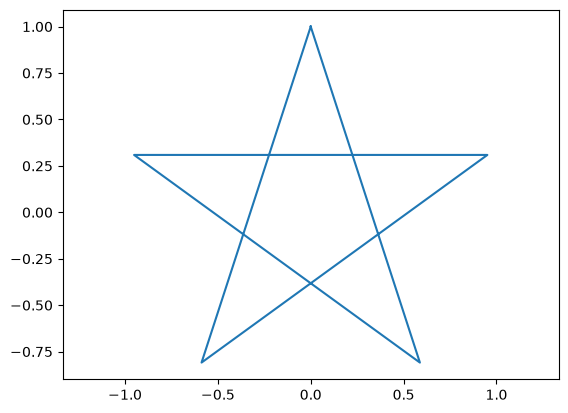

In [4]:
def star(n=5, m=2):
    r = 1
    theta = np.linspace(np.pi/2, 2 * np.pi * m + np.pi/2, n+1)
    x = r * np.cos(theta)
    y = r * np.sin(theta)
    plt.plot(x, y)
    plt.axis('equal')

star(5, 2)

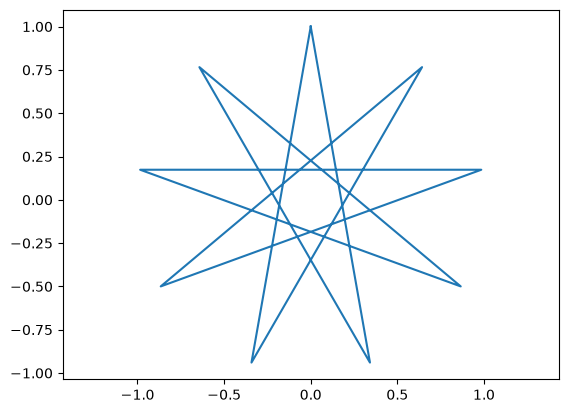

In [6]:
star(9, 4)

4) Any function(s) of your interest

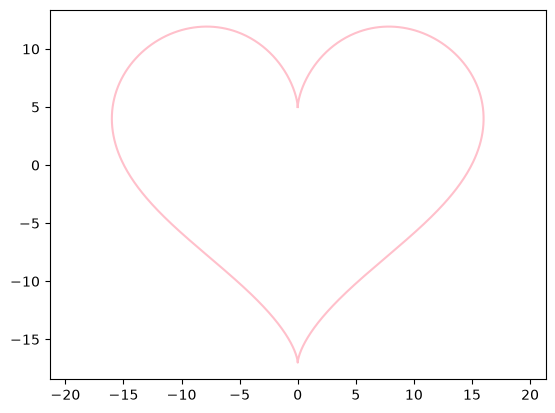

In [14]:
def heart(size=1, points=1000, color="r"):
    t = np.linspace(0, 2 * np.pi, points)
    x = size * 16 * np.sin(t) ** 3
    y = size * (
        13 * np.cos(t)
        - 5 * np.cos(2 * t)
        - 2 * np.cos(3 * t)
        - np.cos(4 * t)
    )
    plt.plot(x, y, color=color)
    plt.axis("equal")

heart(color="pink")

## 2. Classes
1) Extend the `Cell`, `gCell` or `Culture` class with new methods, such as:
* cells with other shapes, e.g. ellipse, polygon,...
* move to avoid overlap with another cell
* connect with another cell like a neuron
* growth based on the environment, e.g., number of neighbors
* ...

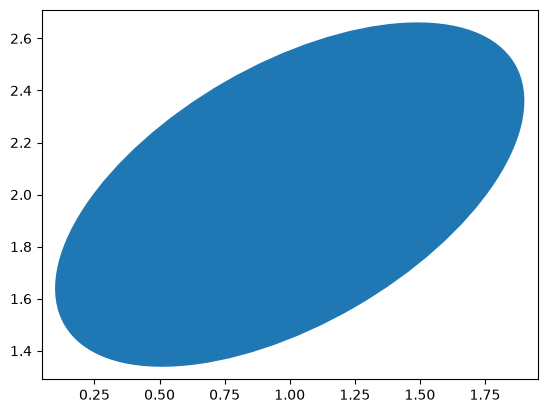

In [22]:
# example of drawing an ellipse
import matplotlib.patches as pat
p = pat.Ellipse(xy=(1,2), width=2, height=1, angle=30)
plt.gca().add_patch(p)
plt.axis('equal');

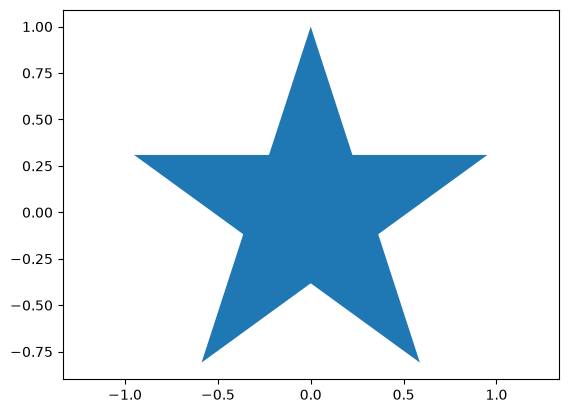

In [23]:
# example of drawing a polygon
xy = np.array([[np.sin(th),np.cos(th)] for th in np.arange(0, 4*np.pi, np.pi*4/5)])
p = pat.Polygon(xy)
plt.gca().add_patch(p)
plt.axis('equal');

In [26]:
class Cell:
    """Class for a cell"""

    def __init__(self, position = [0,0], radius=0.1, color=[1,0,0,0.5]):
        """Make a new cell"""
        self.position = np.array(position)
        self.radius = radius
        self.color = color
     
    def show(self):
        """Visualize as a circule"""
        c = plt.Circle(self.position,self.radius,color=self.color)
        plt.gca().add_patch(c)
        plt.axis('equal')

class dCell(Cell):
    """Class of dividing cell based on Cell class"""

    def divide(self):
        """Divide next to each other"""
        theta = np.random.rand()*2*np.pi
        x_shift = np.cos(theta)*self.radius*2
        y_shift = np.sin(theta)*self.radius*2
        c = dCell(self.position + [x_shift, y_shift], self.radius, self.color)
        return c

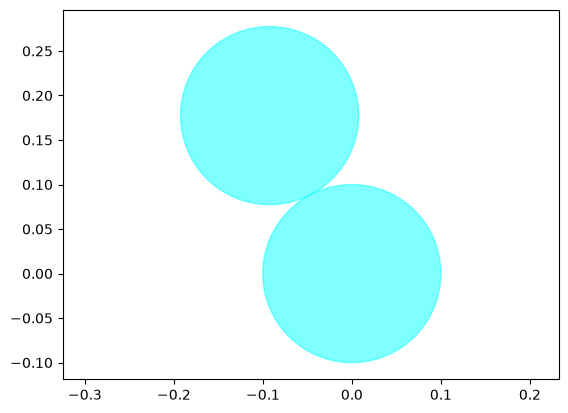

In [27]:
c = dCell([0,0], radius=0.1, color=[0,1,1,0.5])
c.show()
d = c.divide()
d.show()

2) Save the defined class(es) as a module `cell.py`.

3) Import the module and test how it works.

In [98]:
import cell

In [88]:
import importlib

In [99]:
importlib.reload(cell) # This is needed after updating a module

<module 'cell' from '/Users/xiuningzhang/Codes/B50_Scientific_Computing/cell.py'>

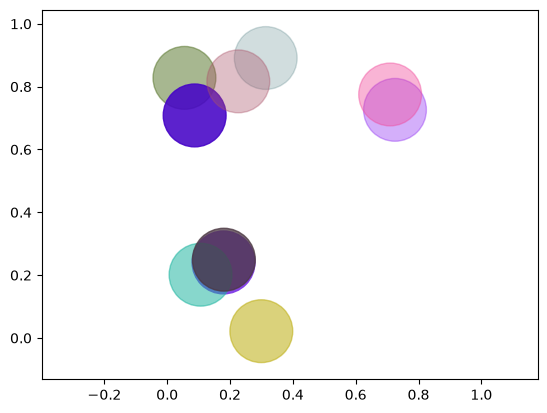

In [112]:
cells = cell.Culture(n=10, radius=0.1)
cells.show()

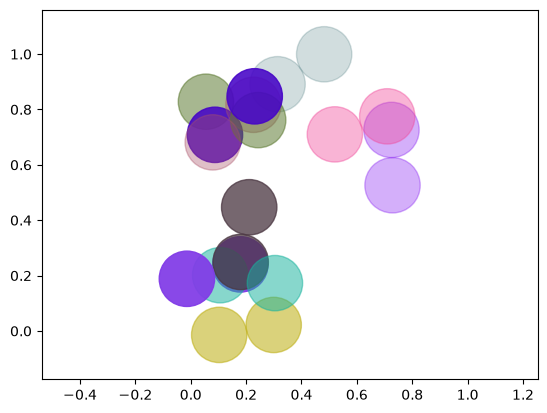

In [113]:
cells.divide()
cells.show()

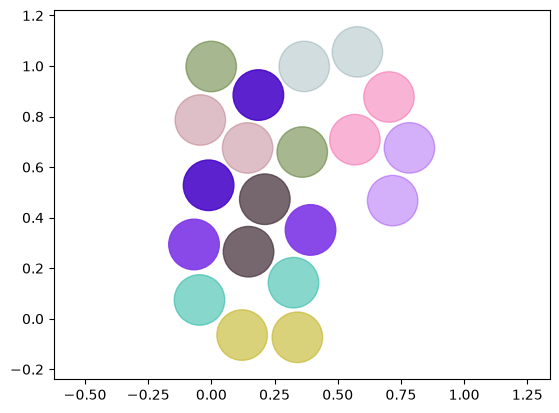

In [114]:
cells.move(scale=(1,1.1))
cells.show()